Detecção de Fraudes em Transações de Cartão de Crédito
Este projeto aplica técnicas de Machine Learning para identificar transações fraudulentas em uma base altamente desbalanceada.

O principal objetivo é avaliar os modelos utilizando métricas adequadas para detecção de fraude, com atenção especial para Precision, Recall e F1-score, em vez de analisar apenas a acurácia.

1. Importação das bibliotecas
Nesta etapa são importadas as bibliotecas utilizadas na manipulação dos dados, visualização, modelagem, balanceamento das classes e explicabilidade do modelo.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    classification_report,
    roc_curve,
    roc_auc_score,
    precision_recall_curve
)

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

from xgboost import XGBClassifier

c:\Users\ARibeir2\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2. Carregamento e exploração do dataset
O dataset contém transações de cartão de crédito classificadas como normais (Class = 0) ou fraudulentas (Class = 1).

As variáveis V1 a V28 foram transformadas por PCA para preservar a privacidade das informações originais.

In [2]:
url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

df = pd.read_csv(url)

df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
df["Class"].value_counts(normalize=True)

Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64

3. Preparação dos dados
Para preparar os dados, foi criada uma transformação logarítmica da variável Amount e também uma versão padronizada.

Em seguida, os dados foram separados em conjuntos de treino e teste utilizando stratify, preservando a proporção de fraudes em ambos os conjuntos.

In [4]:
df["Amount_log"] = np.log1p(df["Amount"])

scaler = StandardScaler()

df["Amount_scaled"] = scaler.fit_transform(
    df[["Amount"]]
)

X = df.drop("Class", axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    stratify=y,
    test_size=0.3,
    random_state=42
)

4. Baseline: Regressão Logística
A Regressão Logística foi utilizada como modelo inicial para estabelecer uma referência de desempenho antes da aplicação de estratégias mais avançadas.

In [5]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.85      0.64      0.73       148

    accuracy                           1.00     85443
   macro avg       0.92      0.82      0.86     85443
weighted avg       1.00      1.00      1.00     85443



c:\Users\ARibeir2\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


5. Curva ROC e AUC
A curva ROC permite analisar o comportamento do classificador em diferentes limiares de decisão. A AUC resume a capacidade do modelo de distinguir entre as classes.

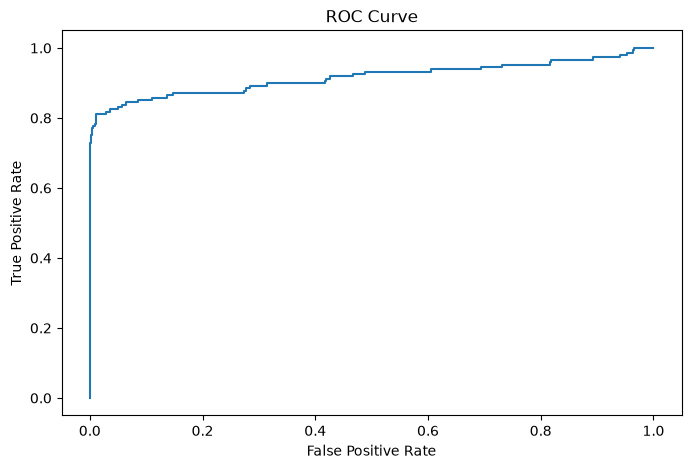

AUC: 0.9151502020808545


In [6]:
y_probs = model.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_probs)

plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr)
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.show()

print("AUC:", roc_auc_score(y_test, y_probs))

6. Precision-Recall Curve
Em problemas altamente desbalanceados, analisar a relação entre Precision e Recall é fundamental para entender o desempenho do modelo sobre a classe minoritária.

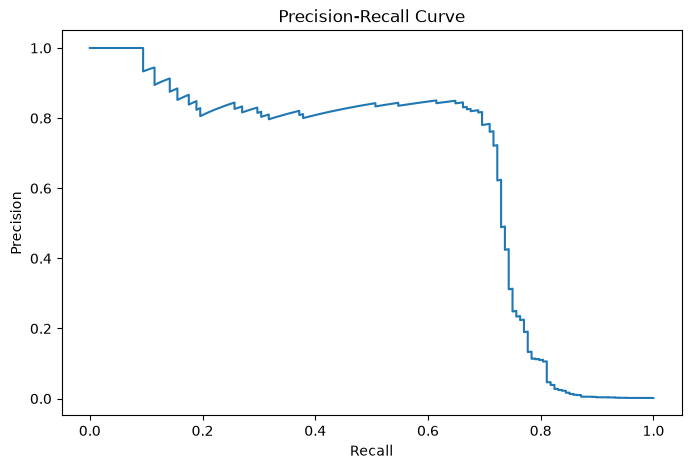

In [7]:
precision, recall, _ = precision_recall_curve(
    y_test,
    y_probs
)

plt.figure(figsize=(8, 5))
plt.plot(recall, precision)

plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")

plt.show()

7. Undersampling
O Random Undersampling reduz a quantidade de observações da classe majoritária durante o treinamento.

O objetivo é aumentar a capacidade do modelo de identificar a classe de fraude e analisar o impacto dessa estratégia sobre Precision, Recall e F1-score.

In [8]:
under = RandomUnderSampler(random_state=42)

X_train_under, y_train_under = under.fit_resample(
    X_train,
    y_train
)

model_under = LogisticRegression(max_iter=1000)

model_under.fit(
    X_train_under,
    y_train_under
)

y_pred_under = model_under.predict(X_test)

print("--- RESULTADO UNDERSAMPLING ---")
print(classification_report(y_test, y_pred_under))

--- RESULTADO UNDERSAMPLING ---
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     85295
           1       0.05      0.88      0.10       148

    accuracy                           0.97     85443
   macro avg       0.53      0.93      0.54     85443
weighted avg       1.00      0.97      0.98     85443



c:\Users\ARibeir2\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


8. Oversampling com SMOTE
O SMOTE cria exemplos sintéticos da classe minoritária no conjunto de treinamento.

A estratégia foi testada para avaliar se o aumento da representação das fraudes poderia melhorar o equilíbrio entre Precision e Recall.

In [9]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

model_smote = LogisticRegression(max_iter=1000)

model_smote.fit(
    X_train_smote,
    y_train_smote
)

y_pred_smote = model_smote.predict(X_test)

print("--- RESULTADO SMOTE ---")
print(classification_report(y_test, y_pred_smote))

--- RESULTADO SMOTE ---
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     85295
           1       0.13      0.85      0.23       148

    accuracy                           0.99     85443
   macro avg       0.56      0.92      0.61     85443
weighted avg       1.00      0.99      0.99     85443



c:\Users\ARibeir2\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


9. Random Forest
O Random Forest foi utilizado como alternativa baseada em árvores, utilizando class_weight="balanced" para considerar o desbalanceamento entre as classes.

In [10]:
rf = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.74      0.80      0.77       148

    accuracy                           1.00     85443
   macro avg       0.87      0.90      0.89     85443
weighted avg       1.00      1.00      1.00     85443



10. Pipeline e ajuste do Threshold
Também foi testado um pipeline com padronização e Regressão Logística.

Além disso, o limiar de decisão foi alterado para 0.30 para observar o impacto dessa mudança sobre a identificação de fraudes.

In [11]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

pipeline.fit(X_train, y_train)

y_pred_pipeline = pipeline.predict(X_test)

threshold = 0.3

y_pred_custom = (y_probs > threshold).astype(int)

print(classification_report(y_test, y_pred_custom))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.83      0.68      0.74       148

    accuracy                           1.00     85443
   macro avg       0.91      0.84      0.87     85443
weighted avg       1.00      1.00      1.00     85443



11. XGBoost
O XGBoost foi utilizado como um modelo mais robusto para classificação.

Foi aplicado scale_pos_weight para aumentar o peso da classe minoritária durante o treinamento.

In [12]:
xgb = XGBClassifier(
    scale_pos_weight=10,
    eval_metric="logloss"
)

xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)

print("--- RESULTADO XGBOOST ---")
print(classification_report(y_test, y_pred_xgb))

--- RESULTADO XGBOOST ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.94      0.78      0.85       148

    accuracy                           1.00     85443
   macro avg       0.97      0.89      0.93     85443
weighted avg       1.00      1.00      1.00     85443



12. Feature Importance
A importância das variáveis permite observar quais características tiveram maior peso dentro do XGBoost.

Como V1 a V28 são componentes obtidos por PCA, a importância indica relevância para o modelo, mas não deve ser interpretada diretamente como uma característica financeira específica.

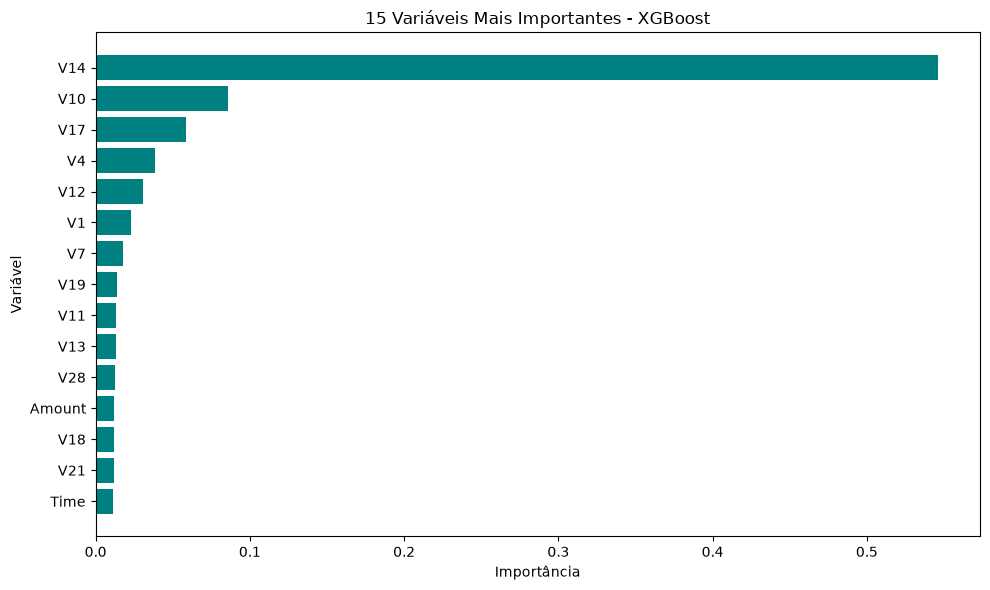

In [13]:
importancias = pd.DataFrame({
    "Variavel": X.columns,
    "Importancia": xgb.feature_importances_
})

importancias = importancias.sort_values(
    by="Importancia",
    ascending=False
).head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    importancias["Variavel"],
    importancias["Importancia"],
    color="teal"
)

plt.gca().invert_yaxis()

plt.title("15 Variáveis Mais Importantes - XGBoost")
plt.xlabel("Importância")
plt.ylabel("Variável")

plt.tight_layout()
plt.show()


13. Otimização com GridSearchCV
Para testar diferentes combinações de hiperparâmetros do XGBoost, foi utilizado GridSearchCV.

Como o objetivo principal do problema é identificar fraudes, o Recall foi utilizado como métrica de otimização.

In [14]:
param_grid = {
    "max_depth": [3, 5],
    "n_estimators": [50, 100]
}

grid = GridSearchCV(
    XGBClassifier(eval_metric="logloss"),
    param_grid,
    scoring="recall",
    cv=3
)

grid.fit(X_train, y_train)

print("Melhor modelo:", grid.best_params_)

Melhor modelo: {'max_depth': 5, 'n_estimators': 100}


14. Explicabilidade com SHAP
SHAP foi utilizado para analisar como as variáveis influenciam as previsões do modelo otimizado.

Essa abordagem complementa a Feature Importance, permitindo observar tanto a relevância das variáveis quanto a direção e magnitude de sua contribuição para diferentes previsões.

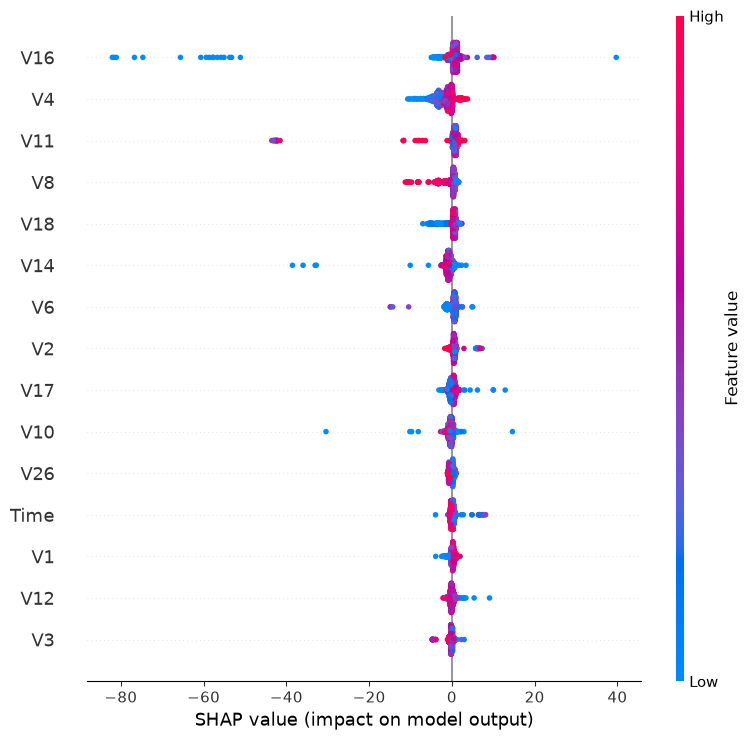

In [15]:
melhor_modelo = grid.best_estimator_

X_shap = X_test.sample(
    n=min(1000, len(X_test)),
    random_state=42
)

explainer = shap.TreeExplainer(melhor_modelo)

shap_values = explainer.shap_values(X_shap)

shap.summary_plot(
    shap_values,
    X_shap,
    max_display=15
)


15. Conclusões
Os experimentos demonstraram como diferentes estratégias podem produzir resultados bastante distintos quando as classes são altamente desbalanceadas.

O Undersampling apresentou o maior Recall para fraude, enquanto o SMOTE proporcionou melhora no equilíbrio entre Precision e Recall.

O XGBoost apresentou um resultado mais equilibrado, alcançando alta Precision e F1-score para a classe de fraude.

Os resultados reforçam que a acurácia isoladamente não é suficiente para avaliar problemas de detecção de fraude. A escolha do modelo depende do equilíbrio desejado entre identificar o maior número possível de fraudes e controlar a quantidade de falsos positivos.

Por fim, Feature Importance e SHAP permitiram adicionar interpretabilidade ao modelo, ajudando a compreender quais variáveis exerceram maior influência sobre as previsões.